In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import preprocessing, model_selection, metrics

# Carga de Datos

## Datos etiquetados

Es el conjunto de datos que ya contienen la clase, este dataset no incluye las características

In [2]:
labeled_data = pd.read_csv("../Data_parcial2_mineria/files_for_lc_classifier_SanchezSaez2020/CSV/labeled_set_lc_classifier_SanchezSaez_2020.csv")
print(f'Tamaño del Dataframe: {labeled_data.shape}')
labeled_data.head()

Tamaño del Dataframe: (123496, 6)


,oid,classALeRCE,ra,dec,source,id_source
0,ZTF19aapcxhy,AGN,154.202129,18.723076,Oh2015,5.877420127343739e+17
1,ZTF18abtmwvo,AGN,46.074050,0.474212,Oh2015,5.880155098263717e+17
2,ZTF18acvgdfy,AGN,134.407409,5.472596,Oh2015,5.877327033915148e+17
3,ZTF19aabvjsi,AGN,132.353298,14.067266,Oh2015,5.877420137987442e+17
4,ZTF18aadyxlg,AGN,125.577004,33.091120,Oh2015,5.880133827239608e+17


In [3]:
labeled_data['classALeRCE'].unique()

<ArrowStringArray>
[           'AGN',         'Blazar',        'CV/Nova',            'CEP',
           'DSCT',              'E',            'LPV', 'Periodic-Other',
            'QSO',            'RRL',           'SLSN',           'SNII',
           'SNIa',          'SNIbc',            'YSO']
Length: 15, dtype: str

## Características

Este dataset incluye las características de todas las fuentes registradas por ZTF (incluye el conjunto de etiquetados y el conjunto sin etiquetar)

In [4]:
features_data = pd.read_csv("../Data_parcial2_mineria/files_for_lc_classifier_SanchezSaez2020/CSV/features_for_lc_classifier_20200609.csv")
print(f'Tamaño del Dataframe: {features_data.shape}')
features_data.head()

Tamaño del Dataframe: (868371, 184)


,oid,MHAOV_Period_1,MHAOV_Period_2,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,...,W4,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,g-r_ml,delta_period_1,delta_period_2
0,ZTF17aaaaavn,0.106021,0.613572,0.078912,0.097860,0.847902,0.673712,2.0,1.0,0.380952,...,9.426,-0.301,1.491,4.239709,2.748709,5.350475,3.859475,1.110766,0.017990,4.895612e-01
1,ZTF17aaaadjh,0.233443,0.233454,0.493980,0.463765,1.000000,1.000000,1.0,1.0,0.279070,...,8.905,-0.125,2.380,4.533904,2.153904,5.281445,2.901445,0.747541,0.000011,5.197596e-08
2,ZTF17aaaadwo,0.060049,0.216873,0.090708,0.196542,0.903625,0.993806,1.0,1.0,0.368421,...,8.848,-0.065,1.602,4.344352,2.742352,5.495974,3.893974,1.151622,0.423044,2.662193e-01
3,ZTF17aaaajjv,526.315748,555.555529,0.539600,0.566276,1.000000,1.000000,14.0,20.0,0.419580,...,5.957,-0.040,0.997,7.765696,6.768696,10.193531,9.196531,2.427835,29.239637,1.437226e-04
4,ZTF17aaaakjt,0.148265,0.148265,0.564867,0.572449,0.999907,0.990501,1.0,1.0,0.338462,...,9.098,-0.027,0.027,3.161238,3.134238,4.298826,4.271826,1.137588,0.000002,2.169809e-06


## Resultados

Este dataset contiene todos los resultados obtenidos en el estudio, específicamente la proabilidad de cada clase y subclase asociada a cada instancia, al igual que las clases predichas por el BRF. Es el dataset que se empleará para realizar las comparaciones

In [5]:
results_data = pd.read_csv("../Data_parcial2_mineria/files_for_lc_classifier_SanchezSaez2020/CSV/ALeRCE_lc_classifier_outputs_ZTF_unlabeled_set_20200609.csv")
print(f'Tamaño del Dataframe: {results_data.shape}')
results_data.head()

Tamaño del Dataframe: (868371, 38)


,oid,ra,dec,Transient_prob_top,Stochastic_prob_top,Periodic_prob_top,SNIa_prob_T,SNIbc_prob_T,SNII_prob_T,SLSN_prob_T,...,YSO_prob,CV/Nova_prob,LPV_prob,E_prob,DSCT_prob,RRL_prob,CEP_prob,Periodic-Other_prob,predicted_class,predicted_class_proba
0,ZTF17aaaaavn,316.742953,49.138344,0.016,0.308,0.676,0.138,0.230,0.302,0.330,...,0.218064,0.045584,0.021632,0.156832,0.018928,0.012168,0.036504,0.429936,Periodic-Other,0.429936
1,ZTF17aaaadjh,75.806810,50.116662,0.000,0.014,0.986,0.130,0.174,0.242,0.454,...,0.001820,0.011844,0.003944,0.658648,0.025636,0.153816,0.096628,0.047328,E,0.658648
2,ZTF17aaaadwo,319.101209,44.968602,0.002,0.124,0.874,0.152,0.228,0.280,0.340,...,0.084320,0.034472,0.013984,0.213256,0.019228,0.022724,0.075164,0.529644,Periodic-Other,0.529644
3,ZTF17aaaajjv,321.297602,47.345766,0.004,0.020,0.976,0.090,0.156,0.224,0.530,...,0.017480,0.000480,0.974048,0.000000,0.000000,0.000000,0.001952,0.000000,LPV,0.974048
4,ZTF17aaaakjt,53.405642,50.727601,0.000,0.036,0.964,0.202,0.246,0.294,0.258,...,0.023040,0.011520,0.009640,0.485856,0.023136,0.117608,0.246784,0.080976,E,0.485856


# Preparación de los Dataframe

Los datos cargados se deben modificar para porder aplicar el modelo.

- df_labeled cruza el dataset de características y el de objetos etiquetados. Esto es para preparar el conjunto de datos de entrenamiento
- df_unlabeled son los datos restantes del segundo dataframe

## Datos Etiquetados

In [6]:
df_labeled_all = labeled_data.merge(features_data, on="oid", how="inner")
print(f'Tamaño del Dataframe: {df_labeled_all.shape}')
df_labeled_all.head()

Tamaño del Dataframe: (123496, 189)


,oid,classALeRCE,ra,dec,source,id_source,MHAOV_Period_1,MHAOV_Period_2,Amplitude_1,Amplitude_2,...,W4,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,g-r_ml,delta_period_1,delta_period_2
0,ZTF19aapcxhy,AGN,154.202129,18.723076,Oh2015,5.877420127343739e+17,0.070100,1.427348,0.068704,0.052665,...,7.992,0.796,2.889,8.106832,5.217832,8.668390,5.779390,0.561558,0.202128,1.155121
1,ZTF18abtmwvo,AGN,46.074050,0.474212,Oh2015,5.880155098263717e+17,0.053205,NaN,0.115177,NaN,...,5.849,0.807,2.964,NaN,NaN,9.126021,6.162021,NaN,0.081005,NaN
2,ZTF18acvgdfy,AGN,134.407409,5.472596,Oh2015,5.877327033915148e+17,0.062636,NaN,0.050608,NaN,...,6.391,0.606,2.876,NaN,NaN,8.483215,5.607215,NaN,0.023222,NaN
3,ZTF19aabvjsi,AGN,132.353298,14.067266,Oh2015,5.877420137987442e+17,NaN,0.055791,NaN,0.028547,...,7.438,0.938,3.017,8.099364,5.082364,NaN,NaN,NaN,NaN,0.529107
4,ZTF18aadyxlg,AGN,125.577004,33.091120,Oh2015,5.880133827239608e+17,NaN,0.054051,NaN,0.021935,...,7.053,0.959,3.021,8.041334,5.020334,NaN,NaN,NaN,NaN,0.277404


Borrar identificadores del primer dataset y solo dejar la clase real

In [7]:
df_labeled_all = df_labeled_all.drop(columns = ["ra", "dec", "source", "id_source"])
df_labeled_all.head()

,oid,classALeRCE,MHAOV_Period_1,MHAOV_Period_2,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,...,W4,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,g-r_ml,delta_period_1,delta_period_2
0,ZTF19aapcxhy,AGN,0.070100,1.427348,0.068704,0.052665,0.665183,0.501831,1.0,1.0,...,7.992,0.796,2.889,8.106832,5.217832,8.668390,5.779390,0.561558,0.202128,1.155121
1,ZTF18abtmwvo,AGN,0.053205,NaN,0.115177,NaN,0.996398,NaN,1.0,NaN,...,5.849,0.807,2.964,NaN,NaN,9.126021,6.162021,NaN,0.081005,NaN
2,ZTF18acvgdfy,AGN,0.062636,NaN,0.050608,NaN,0.353987,NaN,1.0,NaN,...,6.391,0.606,2.876,NaN,NaN,8.483215,5.607215,NaN,0.023222,NaN
3,ZTF19aabvjsi,AGN,NaN,0.055791,NaN,0.028547,NaN,0.494246,NaN,1.0,...,7.438,0.938,3.017,8.099364,5.082364,NaN,NaN,NaN,NaN,0.529107
4,ZTF18aadyxlg,AGN,NaN,0.054051,NaN,0.021935,NaN,0.543918,NaN,1.0,...,7.053,0.959,3.021,8.041334,5.020334,NaN,NaN,NaN,NaN,0.277404


Se definen todas las características especificadas en el artículo:
- Variables de Detección (det)
    - 56 en r
    - 56 en g
    - 12 en multibanda (multi)
- Variables de no Detección (nodet)
    - 9 por banda
- Otras (coordenadas y comparación con AllWISE)
    - 10 en total

In [8]:
df_labeled_all = df_labeled_all.rename(columns = {"Period_fit": "PPE"})

det = ["delta_period","IAR_phi","MHPS_low","MHPS_high","MHPS_ratio",
       "positive_fraction","delta_mag_fid","ExcessVar","GP_DRW_tau","GP_DRW_sigma",
       *[f"Harmonics_mag_{k}" for k in range(1,8)],
       *[f"Harmonics_phase_{k}" for k in range(2,8)], "Harmonics_mse",
       "Pvar","SF_ML_amplitude","SF_ML_gamma",
       "SPM_A","SPM_t0","SPM_gamma","SPM_beta","SPM_tau_rise","SPM_tau_fall","SPM_chi",
       "Amplitude","AndersonDarling","Autocor_length","Beyond1Std","Con","Eta_e","Gskew",
       "LinearTrend","MaxSlope","Meanvariance","MedianAbsDev","MedianBRP","PairSlopeTrend",
       "PercentAmplitude","Psi_CS","Psi_eta","Q31","Rcs","Skew","SmallKurtosis","Std","StetsonK"]   # 56

nodet = ["dmag_first_det_fid","dmag_non_det_fid","last_diffmaglim_before_fid",
         "max_diffmaglim_before_fid","max_diffmaglim_after_fid",
         "median_diffmaglim_before_fid","median_diffmaglim_after_fid",
         "n_non_det_before_fid","n_non_det_after_fid"]                                          # 9

por_banda = [f"{n}_{b}" for n in det + nodet for b in (1, 2)]                                 # 130

multi = ["Multiband_period","PPE","Power_rate_1/2","Power_rate_1/3","Power_rate_1/4",
         "Power_rate_2","Power_rate_3","Power_rate_4",
         "g-r_max","g-r_max_corr","g-r_mean","g-r_mean_corr"]                                   # 12

otras = ["gal_b","gal_l","W1-W2","W2-W3","g-W2","g-W3","r-W2","r-W3","sgscore1","rb"]          # 10

esperadas = por_banda + multi + otras                                                            # 152 registradas en el artículo
cols = set(df_labeled_all.columns)

sobrantes = sorted(cols - set(esperadas) - {"oid", "classALeRCE"})

print("faltan :", sorted(set(esperadas) - cols))
print("sobran :", sobrantes)

faltan : []
sobran : ['MHAOV_Period_1', 'MHAOV_Period_2', 'MHPS_PN_flag_1', 'MHPS_PN_flag_2', 'MHPS_non_zero_1', 'MHPS_non_zero_2', 'Mean_1', 'Mean_2', 'W1', 'W2', 'W3', 'W4', 'delta_mjd_fid_1', 'delta_mjd_fid_2', 'first_mag_1', 'first_mag_2', 'g-r_ml', 'iqr_1', 'iqr_2', 'last_mjd_before_fid_1', 'last_mjd_before_fid_2', 'mean_mag_1', 'mean_mag_2', 'min_mag_1', 'min_mag_2', 'n_det_1', 'n_det_2', 'n_neg_1', 'n_neg_2', 'n_pos_1', 'n_pos_2']


PPE se registra en el dataset como "Period_fit". El resto son características que no se emplean para el entrenamiento, si no que se usan para realizar algunas de las graficas; o son datos sin procesar que se usaron para generar las demas características, como W1, W2, etc.

Dado que se está construyendo el dataframe para entrenar el modelo estas características se van a eliminar

In [9]:
df_labeled = df_labeled_all.drop(columns = sobrantes)
df_labeled.head()

,oid,classALeRCE,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,Beyond1Std_2,...,rb,sgscore1,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,delta_period_1,delta_period_2
0,ZTF19aapcxhy,AGN,0.068704,0.052665,0.665183,0.501831,1.0,1.0,0.250000,0.307692,...,0.780000,0.013542,0.796,2.889,8.106832,5.217832,8.668390,5.779390,0.202128,1.155121
1,ZTF18abtmwvo,AGN,0.115177,NaN,0.996398,NaN,1.0,NaN,0.428571,NaN,...,0.717857,0.216488,0.807,2.964,NaN,NaN,9.126021,6.162021,0.081005,NaN
2,ZTF18acvgdfy,AGN,0.050608,NaN,0.353987,NaN,1.0,NaN,0.500000,NaN,...,0.683333,0.088542,0.606,2.876,NaN,NaN,8.483215,5.607215,0.023222,NaN
3,ZTF19aabvjsi,AGN,NaN,0.028547,NaN,0.494246,NaN,1.0,NaN,0.333333,...,0.683333,0.035875,0.938,3.017,8.099364,5.082364,NaN,NaN,NaN,0.529107
4,ZTF18aadyxlg,AGN,NaN,0.021935,NaN,0.543918,NaN,1.0,NaN,0.500000,...,0.683333,0.161542,0.959,3.021,8.041334,5.020334,NaN,NaN,NaN,0.277404


In [10]:
#mover la clase real hacia la ultima posición para seguir el estándar

# Extraer la columna de la posición 1 y quitarla de su sitio actual
columna = df_labeled['classALeRCE']
df_labeled.drop(columns='classALeRCE', inplace=True)

df_labeled = df_labeled.join(columna)

df_labeled.head()

,oid,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,Beyond1Std_2,Con_1,...,sgscore1,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,delta_period_1,delta_period_2,classALeRCE
0,ZTF19aapcxhy,0.068704,0.052665,0.665183,0.501831,1.0,1.0,0.250000,0.307692,0.0,...,0.013542,0.796,2.889,8.106832,5.217832,8.668390,5.779390,0.202128,1.155121,AGN
1,ZTF18abtmwvo,0.115177,NaN,0.996398,NaN,1.0,NaN,0.428571,NaN,0.0,...,0.216488,0.807,2.964,NaN,NaN,9.126021,6.162021,0.081005,NaN,AGN
2,ZTF18acvgdfy,0.050608,NaN,0.353987,NaN,1.0,NaN,0.500000,NaN,0.0,...,0.088542,0.606,2.876,NaN,NaN,8.483215,5.607215,0.023222,NaN,AGN
3,ZTF19aabvjsi,NaN,0.028547,NaN,0.494246,NaN,1.0,NaN,0.333333,NaN,...,0.035875,0.938,3.017,8.099364,5.082364,NaN,NaN,NaN,0.529107,AGN
4,ZTF18aadyxlg,NaN,0.021935,NaN,0.543918,NaN,1.0,NaN,0.500000,NaN,...,0.161542,0.959,3.021,8.041334,5.020334,NaN,NaN,NaN,0.277404,AGN


## Datos sin Etiquetar

Se deben tomar los datos restantes del segundo dataframe

In [11]:
df_unlabeled_all = features_data[~features_data["oid"].isin(labeled_data["oid"])].copy()

In [12]:
print(f'Tamaño del Dataframe: {df_unlabeled_all.shape}')
df_unlabeled_all.head()

Tamaño del Dataframe: (744875, 184)


,oid,MHAOV_Period_1,MHAOV_Period_2,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,...,W4,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,g-r_ml,delta_period_1,delta_period_2
0,ZTF17aaaaavn,0.106021,0.613572,0.078912,0.097860,0.847902,0.673712,2.0,1.0,0.380952,...,9.426,-0.301,1.491,4.239709,2.748709,5.350475,3.859475,1.110766,0.017990,4.895612e-01
1,ZTF17aaaadjh,0.233443,0.233454,0.493980,0.463765,1.000000,1.000000,1.0,1.0,0.279070,...,8.905,-0.125,2.380,4.533904,2.153904,5.281445,2.901445,0.747541,0.000011,5.197596e-08
2,ZTF17aaaadwo,0.060049,0.216873,0.090708,0.196542,0.903625,0.993806,1.0,1.0,0.368421,...,8.848,-0.065,1.602,4.344352,2.742352,5.495974,3.893974,1.151622,0.423044,2.662193e-01
3,ZTF17aaaajjv,526.315748,555.555529,0.539600,0.566276,1.000000,1.000000,14.0,20.0,0.419580,...,5.957,-0.040,0.997,7.765696,6.768696,10.193531,9.196531,2.427835,29.239637,1.437226e-04
4,ZTF17aaaakjt,0.148265,0.148265,0.564867,0.572449,0.999907,0.990501,1.0,1.0,0.338462,...,9.098,-0.027,0.027,3.161238,3.134238,4.298826,4.271826,1.137588,0.000002,2.169809e-06


Se borran las mismas características del dataframe etiquetado

In [13]:
df_unlabeled = df_unlabeled_all.drop(columns = sobrantes)

In [14]:
df_unlabeled.head()

,oid,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,Beyond1Std_2,Con_1,...,rb,sgscore1,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,delta_period_1,delta_period_2
0,ZTF17aaaaavn,0.078912,0.097860,0.847902,0.673712,2.0,1.0,0.380952,0.428571,0.0,...,0.738809,0.989375,-0.301,1.491,4.239709,2.748709,5.350475,3.859475,0.017990,4.895612e-01
1,ZTF17aaaadjh,0.493980,0.463765,1.000000,1.000000,1.0,1.0,0.279070,0.293103,0.0,...,0.742857,1.000000,-0.125,2.380,4.533904,2.153904,5.281445,2.901445,0.000011,5.197596e-08
2,ZTF17aaaadwo,0.090708,0.196542,0.903625,0.993806,1.0,1.0,0.368421,0.285714,0.0,...,0.737143,0.992667,-0.065,1.602,4.344352,2.742352,5.495974,3.893974,0.423044,2.662193e-01
3,ZTF17aaaajjv,0.539600,0.566276,1.000000,1.000000,14.0,20.0,0.419580,0.481203,0.0,...,0.743333,1.000000,-0.040,0.997,7.765696,6.768696,10.193531,9.196531,29.239637,1.437226e-04
4,ZTF17aaaakjt,0.564867,0.572449,0.999907,0.990501,1.0,1.0,0.338462,0.350000,0.0,...,0.818571,0.975000,-0.027,0.027,3.161238,3.134238,4.298826,4.271826,0.000002,2.169809e-06


# Limpieza de Datos

En el artículo no se especifica ningun proceso de eliminación o tratamiento de outliners.

Por otro lado, se menciona que la solución que se dio para lidiar con los datos faltantes de las fuentes fue simplemente llenarlos con el valor -999, esto aplica para todas las clases. No se especifica ningún otro proceso como llenar con media o mediana.

Como se busca replicar los resultados del artículo, se aplicará el mismo proceso

In [15]:
df_labeled.fillna(-999, inplace = True)

,oid,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,Beyond1Std_2,Con_1,...,sgscore1,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,delta_period_1,delta_period_2,classALeRCE
0,ZTF19aapcxhy,0.068704,0.052665,0.665183,0.501831,1.0,1.0,0.250000,0.307692,0.000000,...,0.013542,0.796,2.889,8.106832,5.217832,8.668390,5.779390,0.202128,1.155121e+00,AGN
1,ZTF18abtmwvo,0.115177,-999.000000,0.996398,-999.000000,1.0,-999.0,0.428571,-999.000000,0.000000,...,0.216488,0.807,2.964,-999.000000,-999.000000,9.126021,6.162021,0.081005,-9.990000e+02,AGN
2,ZTF18acvgdfy,0.050608,-999.000000,0.353987,-999.000000,1.0,-999.0,0.500000,-999.000000,0.000000,...,0.088542,0.606,2.876,-999.000000,-999.000000,8.483215,5.607215,0.023222,-9.990000e+02,AGN
3,ZTF19aabvjsi,-999.000000,0.028547,-999.000000,0.494246,-999.0,1.0,-999.000000,0.333333,-999.000000,...,0.035875,0.938,3.017,8.099364,5.082364,-999.000000,-999.000000,-999.000000,5.291067e-01,AGN
4,ZTF18aadyxlg,-999.000000,0.021935,-999.000000,0.543918,-999.0,1.0,-999.000000,0.500000,-999.000000,...,0.161542,0.959,3.021,8.041334,5.020334,-999.000000,-999.000000,-999.000000,2.774040e-01,AGN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123491,ZTF17aaanrhv,0.550853,0.608579,0.999999,0.994835,1.0,1.0,0.254545,0.269231,0.000000,...,0.983661,0.194,0.476,4.152745,3.676745,4.918487,4.442487,2.994334,2.463548e+00,YSO
123492,ZTF18aabgmld,0.375521,-999.000000,0.510218,-999.000000,2.0,-999.0,0.324324,-999.000000,0.000000,...,0.970702,0.576,2.730,-999.000000,-999.000000,8.854882,6.124882,0.000005,-9.990000e+02,YSO
123493,ZTF17aaarpje,0.684785,0.358616,1.000000,1.000000,3.0,2.0,0.172414,0.363636,0.017857,...,0.995833,0.312,1.949,6.325936,4.376936,7.583325,5.634325,0.092603,2.055963e-01,YSO
123494,ZTF18actawih,0.215637,-999.000000,0.904850,-999.000000,1.0,-999.0,0.300000,-999.000000,0.000000,...,0.968494,-999.000,-999.000,-999.000000,-999.000000,-999.000000,-999.000000,0.000001,-9.990000e+02,YSO


In [16]:
df_unlabeled.fillna(-999, inplace = True)

,oid,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,Beyond1Std_2,Con_1,...,rb,sgscore1,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,delta_period_1,delta_period_2
0,ZTF17aaaaavn,0.078912,0.097860,0.847902,0.673712,2.0,1.0,0.380952,0.428571,0.0,...,0.738809,0.989375,-0.301,1.491,4.239709,2.748709,5.350475,3.859475,1.799006e-02,4.895612e-01
1,ZTF17aaaadjh,0.493980,0.463765,1.000000,1.000000,1.0,1.0,0.279070,0.293103,0.0,...,0.742857,1.000000,-0.125,2.380,4.533904,2.153904,5.281445,2.901445,1.086247e-05,5.197596e-08
2,ZTF17aaaadwo,0.090708,0.196542,0.903625,0.993806,1.0,1.0,0.368421,0.285714,0.0,...,0.737143,0.992667,-0.065,1.602,4.344352,2.742352,5.495974,3.893974,4.230435e-01,2.662193e-01
3,ZTF17aaaajjv,0.539600,0.566276,1.000000,1.000000,14.0,20.0,0.419580,0.481203,0.0,...,0.743333,1.000000,-0.040,0.997,7.765696,6.768696,10.193531,9.196531,2.923964e+01,1.437226e-04
4,ZTF17aaaakjt,0.564867,0.572449,0.999907,0.990501,1.0,1.0,0.338462,0.350000,0.0,...,0.818571,0.975000,-0.027,0.027,3.161238,3.134238,4.298826,4.271826,2.169809e-06,2.169809e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
868365,ZTF20aaxaoux,0.514642,0.205237,0.980084,0.223971,6.0,3.0,0.297297,0.307692,0.0,...,0.800000,0.001667,0.205,4.304,6.705447,2.401447,6.854509,2.550509,2.010602e-03,2.467718e+01
868366,ZTF20aaxdjho,0.052910,-999.000000,0.567467,-999.000000,1.0,-999.0,0.428571,-999.000000,0.0,...,0.760000,0.087089,1.002,2.974,-999.000000,-999.000000,9.217011,6.243011,4.489011e-04,-9.990000e+02
868367,ZTF20aayguev,0.032849,-999.000000,0.332489,-999.000000,1.0,-999.0,0.142857,-999.000000,0.0,...,0.907143,1.000000,1.305,3.493,-999.000000,-999.000000,7.658437,4.165437,5.889582e-09,-9.990000e+02
868368,ZTF20abaqkji,0.083635,0.059424,0.480592,0.515624,1.0,1.0,0.428571,0.300000,0.0,...,0.810000,0.000000,0.219,2.564,5.831268,3.267268,6.503208,3.939208,8.727257e-03,6.528916e-03


# Añadir Clase del Primer Nivel de BRF

El artículo aplica balanced random forest al modelo en dos niveles. En el primero se clasifican los objetos en 3 clases (estocástica, transición o periódica), porteriormente en el segundo nivel se aplica un modelo BRF diferente para cada una de las 3 clases para colocar cada objeto en una de las 15 subclases.

Por esta razón, basándose en el artículo, se debe añadir una columna target en el conjunto etiquetado que diga a cual de las 3 clases pertence cada fuente

In [17]:
df_labeled['classALeRCE'].unique()

<ArrowStringArray>
[           'AGN',         'Blazar',        'CV/Nova',            'CEP',
           'DSCT',              'E',            'LPV', 'Periodic-Other',
            'QSO',            'RRL',           'SLSN',           'SNII',
           'SNIa',          'SNIbc',            'YSO']
Length: 15, dtype: str

In [18]:
# Diccionario de cada clase del primer nivel segun el artículo

mapa = {
    'SNIa':'Transient', 'SNIbc':'Transient', 'SNII':'Transient', 'SLSN':'Transient',
    'CV/Nova':'Stochastic', 'Blazar':'Stochastic', 'QSO':'Stochastic', 'AGN':'Stochastic', 'YSO':'Stochastic',
    'LPV':'Periodic', 'CEP':'Periodic', 'RRL':'Periodic', 'DSCT':'Periodic', 'E':'Periodic', 'Periodic-Other':'Periodic'
}

# Agregar la columna con las 3 clases

df_labeled["classTop"] = df_labeled["classALeRCE"].map(mapa)
df_labeled.reindex()

/tmp/ipykernel_89/3150291460.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_labeled["classTop"] = df_labeled["classALeRCE"].map(mapa)


,oid,Amplitude_1,Amplitude_2,AndersonDarling_1,AndersonDarling_2,Autocor_length_1,Autocor_length_2,Beyond1Std_1,Beyond1Std_2,Con_1,...,W1-W2,W2-W3,r-W3,r-W2,g-W3,g-W2,delta_period_1,delta_period_2,classALeRCE,classTop
0,ZTF19aapcxhy,0.068704,0.052665,0.665183,0.501831,1.0,1.0,0.250000,0.307692,0.000000,...,0.796,2.889,8.106832,5.217832,8.668390,5.779390,0.202128,1.155121e+00,AGN,Stochastic
1,ZTF18abtmwvo,0.115177,-999.000000,0.996398,-999.000000,1.0,-999.0,0.428571,-999.000000,0.000000,...,0.807,2.964,-999.000000,-999.000000,9.126021,6.162021,0.081005,-9.990000e+02,AGN,Stochastic
2,ZTF18acvgdfy,0.050608,-999.000000,0.353987,-999.000000,1.0,-999.0,0.500000,-999.000000,0.000000,...,0.606,2.876,-999.000000,-999.000000,8.483215,5.607215,0.023222,-9.990000e+02,AGN,Stochastic
3,ZTF19aabvjsi,-999.000000,0.028547,-999.000000,0.494246,-999.0,1.0,-999.000000,0.333333,-999.000000,...,0.938,3.017,8.099364,5.082364,-999.000000,-999.000000,-999.000000,5.291067e-01,AGN,Stochastic
4,ZTF18aadyxlg,-999.000000,0.021935,-999.000000,0.543918,-999.0,1.0,-999.000000,0.500000,-999.000000,...,0.959,3.021,8.041334,5.020334,-999.000000,-999.000000,-999.000000,2.774040e-01,AGN,Stochastic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123491,ZTF17aaanrhv,0.550853,0.608579,0.999999,0.994835,1.0,1.0,0.254545,0.269231,0.000000,...,0.194,0.476,4.152745,3.676745,4.918487,4.442487,2.994334,2.463548e+00,YSO,Stochastic
123492,ZTF18aabgmld,0.375521,-999.000000,0.510218,-999.000000,2.0,-999.0,0.324324,-999.000000,0.000000,...,0.576,2.730,-999.000000,-999.000000,8.854882,6.124882,0.000005,-9.990000e+02,YSO,Stochastic
123493,ZTF17aaarpje,0.684785,0.358616,1.000000,1.000000,3.0,2.0,0.172414,0.363636,0.017857,...,0.312,1.949,6.325936,4.376936,7.583325,5.634325,0.092603,2.055963e-01,YSO,Stochastic
123494,ZTF18actawih,0.215637,-999.000000,0.904850,-999.000000,1.0,-999.0,0.300000,-999.000000,0.000000,...,-999.000,-999.000,-999.000000,-999.000000,-999.000000,-999.000000,0.000001,-9.990000e+02,YSO,Stochastic


# Separación de Datos

Las matrices finalizadas en 1 corresponden a las del primer nivel, las terminadas en 2 a las del segundo

In [19]:
X_BRF1 = df_labeled.iloc[:, 1:153]
y_BRF1, y_BRF2 = df_labeled['classTop'], df_labeled['classALeRCE']

In [20]:
X_BRF1.shape

(123496, 152)

In [21]:
y_BRF1.head()

0    Stochastic
1    Stochastic
2    Stochastic
3    Stochastic
4    Stochastic
Name: classTop, dtype: str

In [22]:
y_BRF2.head()

0    AGN
1    AGN
2    AGN
3    AGN
4    AGN
Name: classALeRCE, dtype: str

## Partición

En el artículo se especifica que se utilizó una partición de 20/80

In [23]:
from sklearn.model_selection import train_test_split

X_tr, X_ts, y_tr1, y_ts1, y_tr2, y_ts2 = train_test_split(X_BRF1,
                                                    y_BRF1, y_BRF2,
                                                    test_size=0.20,
                                                    random_state=40)

Hay que separar los datos de acuerdo a cada clase, para aplicarlos al segundo nivel y clasificar las subclases

In [24]:
X_tr_Stochastic = X_tr.loc[y_tr1 == 'Stochastic', :]
y_tr_Stochastic = y_tr2.loc[y_tr1 == 'Stochastic']

X_tr_Periodic = X_tr.loc[y_tr1 == 'Periodic', :]
y_tr_Periodic = y_tr2.loc[y_tr1 == 'Periodic']

X_tr_Transient = X_tr.loc[y_tr1 == 'Transient', :]
y_tr_Transient = y_tr2.loc[y_tr1 == 'Transient']

X_ts_Stochastic = X_ts
X_ts_Periodic = X_ts
X_ts_Transient = X_ts

print(f'Stochastic sub-classes: {y_tr_Stochastic.unique()} \n')
print(f'Periodic sub-classes: {y_tr_Periodic.unique()} \n')
print(f'Transient sub-classes: {y_tr_Transient.unique()} \n')

Stochastic sub-classes: <ArrowStringArray>
['YSO', 'AGN', 'QSO', 'CV/Nova', 'Blazar']
Length: 5, dtype: str 

Periodic sub-classes: <ArrowStringArray>
['E', 'LPV', 'RRL', 'CEP', 'Periodic-Other', 'DSCT']
Length: 6, dtype: str 

Transient sub-classes: <ArrowStringArray>
['SNIa', 'SNIbc', 'SNII', 'SLSN']
Length: 4, dtype: str 



In [25]:
labels_classTop = ['Transient','Stochastic','Periodic']
labels_classALeRCE = ['SNIa', 'SNIbc', 'SNII', 'SLSN','QSO','AGN', 'Blazar', 'YSO','CV/Nova',
                       'LPV', 'E', 'DSCT', 'RRL', 'CEP','Periodic-Other']

## Definir Función para Graficar Matriz de Confusión e Importancia de Características

In [26]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_confusionMatrix(y_true, y_pred, labels, title, figsize = (10, 9)):
    
    print(classification_report(y_true, y_pred))
    
    print("Accuracy:", "%0.2f" % metrics.accuracy_score(y_true, y_pred))
    print("Balanced accuracy:","%0.2f" %  metrics.balanced_accuracy_score(y_true, y_pred))
    
    print("macro precision: ","%0.2f" %  metrics.precision_score(y_true, y_pred, average='macro'))
    print("macro recall: ","%0.2f" %  metrics.recall_score(y_true, y_pred, average='macro'))
    print("macro F1: ","%0.2f" %  metrics.f1_score(y_true, y_pred, average='macro'))
        
    cm = confusion_matrix(y_true, y_pred, normalize='true', labels = labels)*100
    
    # Renderizar la matriz visualmente
    fig, ax = plt.subplots(figsize=figsize)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap='Blues', values_format='.0f', colorbar=True,
              xticks_rotation=45, ax=ax)
    disp.im_.set_clim(0, 100)   #definir los colores en el rango de 0 a 100
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

def plot_feature_importances(model, feature_names, title):
    I = np.argsort(model.feature_importances_)[::-1]
    I = I[0:60]
    for i in I[0:30]:
        print(feature_names[i], "& %.3f" % (model.feature_importances_[i]))
    fig, ax = plt.subplots(figsize=(16, 5), tight_layout=True)
    x_plot = np.arange(len(I))
    plt.xticks(x_plot, [feature_names[i] for i in I], rotation='vertical')
    ax.bar(x_plot, height=model.feature_importances_[I]);
    plt.title(title)
    plt.show()

# BRF de Dos Niveles

## BRF Primer Nivel

In [27]:
from imblearn.ensemble import BalancedRandomForestClassifier as RandomForestClassifier

# Estos hiperparámetros son extraidos directamente del código publicado en el artículo
BRF1 = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',   #en el artículo se coloca 'auto', pero son lo mismo segun la documentación de imblearn
            max_depth=None,
            n_jobs=-1,
            bootstrap=True,
            class_weight='balanced_subsample',
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1
    )

BRF1.fit(X_tr, y_tr1)

y_true, y_pred = y_ts1, BRF1.predict(X_ts)
y_pred_proba_BRF1 = BRF1.predict_proba(X_ts)

#organizar por probabilidad
classes_order_proba_BRF1 = BRF1.classes_
print(classes_order_proba_BRF1)

features = list(X_tr)

['Periodic' 'Stochastic' 'Transient']


### Matriz de Confusión

              precision    recall  f1-score   support

    Periodic       0.99      1.00      0.99     17373
  Stochastic       0.99      0.96      0.98      6979
   Transient       0.89      1.00      0.94       348

    accuracy                           0.99     24700
   macro avg       0.96      0.99      0.97     24700
weighted avg       0.99      0.99      0.99     24700

Accuracy: 0.99
Balanced accuracy: 0.99
macro precision:  0.96
macro recall:  0.99
macro F1:  0.97


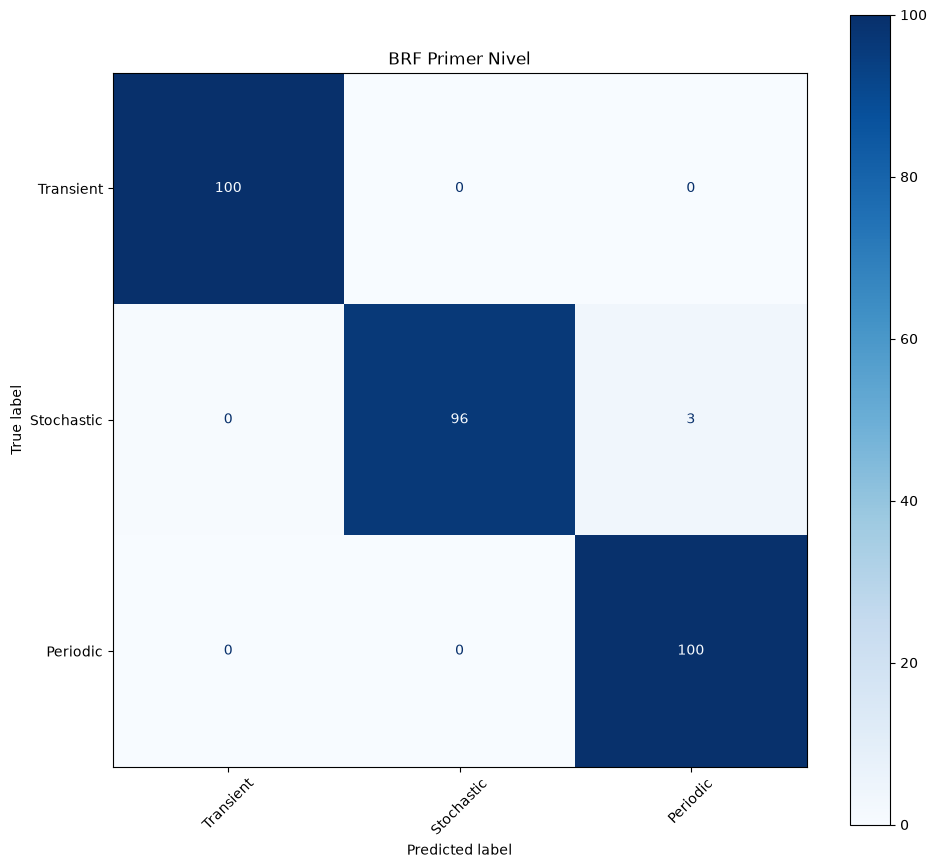

In [28]:
plot_confusionMatrix(y_true, y_pred, labels_classTop, "BRF Primer Nivel")

### Importancia de las Características para BRF1

W1-W2 & 0.085
positive_fraction_2 & 0.051
sgscore1 & 0.051
positive_fraction_1 & 0.049
LinearTrend_2 & 0.033
SPM_chi_1 & 0.032
g-W3 & 0.032
W2-W3 & 0.032
g-W2 & 0.030
SPM_beta_1 & 0.026
SPM_tau_rise_1 & 0.026
SPM_A_1 & 0.026
SPM_chi_2 & 0.025
n_non_det_after_fid_2 & 0.024
SPM_A_2 & 0.021
ExcessVar_2 & 0.019
SPM_tau_rise_2 & 0.018
Rcs_2 & 0.015
ExcessVar_1 & 0.015
r-W2 & 0.015
SPM_tau_fall_1 & 0.014
r-W3 & 0.014
GP_DRW_sigma_2 & 0.011
Meanvariance_2 & 0.011
SPM_beta_2 & 0.011
LinearTrend_1 & 0.011
SPM_t0_1 & 0.010
Pvar_2 & 0.010
Std_2 & 0.010
g-r_mean_corr & 0.009


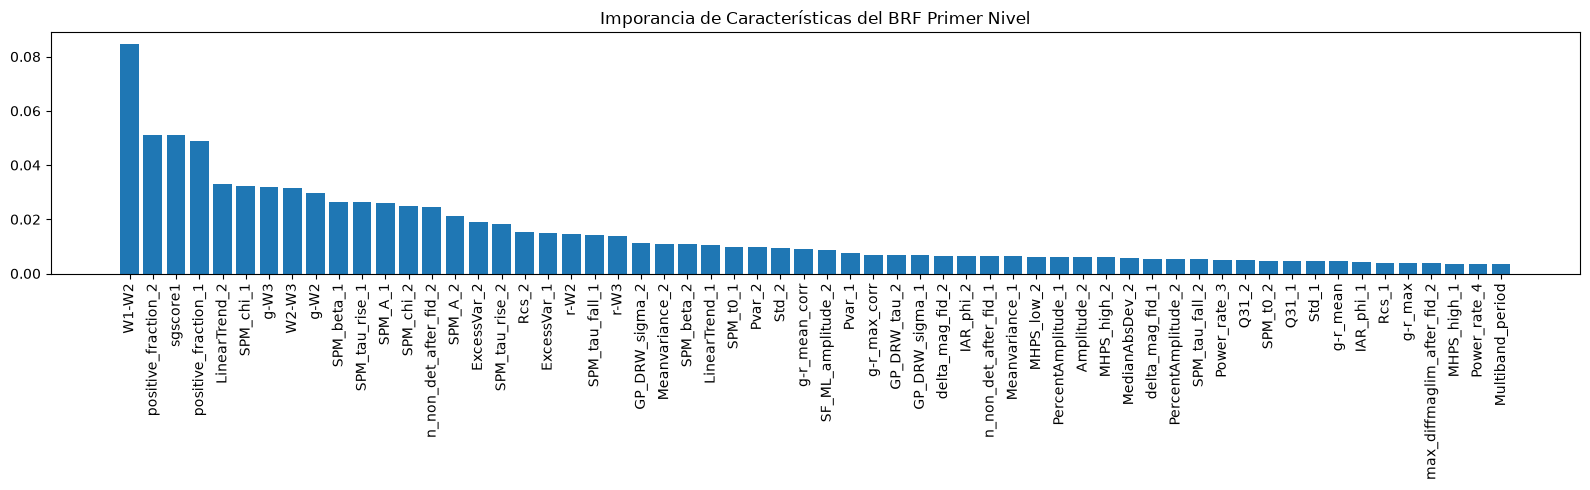

In [29]:
plot_feature_importances(BRF1, features, "Imporancia de Características del BRF Primer Nivel")

## BRF Segundo Nivel

### BRF Periodic

In [30]:
BRF2_periodic = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_periodic.fit(X_tr_Periodic, y_tr_Periodic)

y_true_periodic, y_pred_periodic = y_ts2, BRF2_periodic.predict(X_ts_Periodic)
y_pred_proba_periodic = BRF2_periodic.predict_proba(X_ts_Periodic)

#organizar por probabilidad
classes_order_proba_periodic = BRF2_periodic.classes_
print(classes_order_proba_periodic)

features_periodic = list(X_tr_Periodic)

['CEP' 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


Multiband_period & 0.091
g-W2 & 0.059
g-r_max_corr & 0.031
r-W2 & 0.031
g-r_mean & 0.031
g-W3 & 0.028
g-r_mean_corr & 0.027
g-r_max & 0.027
IAR_phi_1 & 0.021
GP_DRW_tau_1 & 0.019
Amplitude_1 & 0.018
delta_mag_fid_1 & 0.017
ExcessVar_1 & 0.016
Meanvariance_1 & 0.016
r-W3 & 0.015
Std_1 & 0.015
GP_DRW_sigma_1 & 0.014
GP_DRW_tau_2 & 0.014
PercentAmplitude_1 & 0.012
W1-W2 & 0.009
delta_mag_fid_2 & 0.009
Gskew_1 & 0.009
IAR_phi_2 & 0.008
W2-W3 & 0.008
SF_ML_gamma_1 & 0.008
SPM_A_1 & 0.008
Autocor_length_1 & 0.008
SF_ML_amplitude_1 & 0.008
Q31_1 & 0.007
MedianAbsDev_1 & 0.007


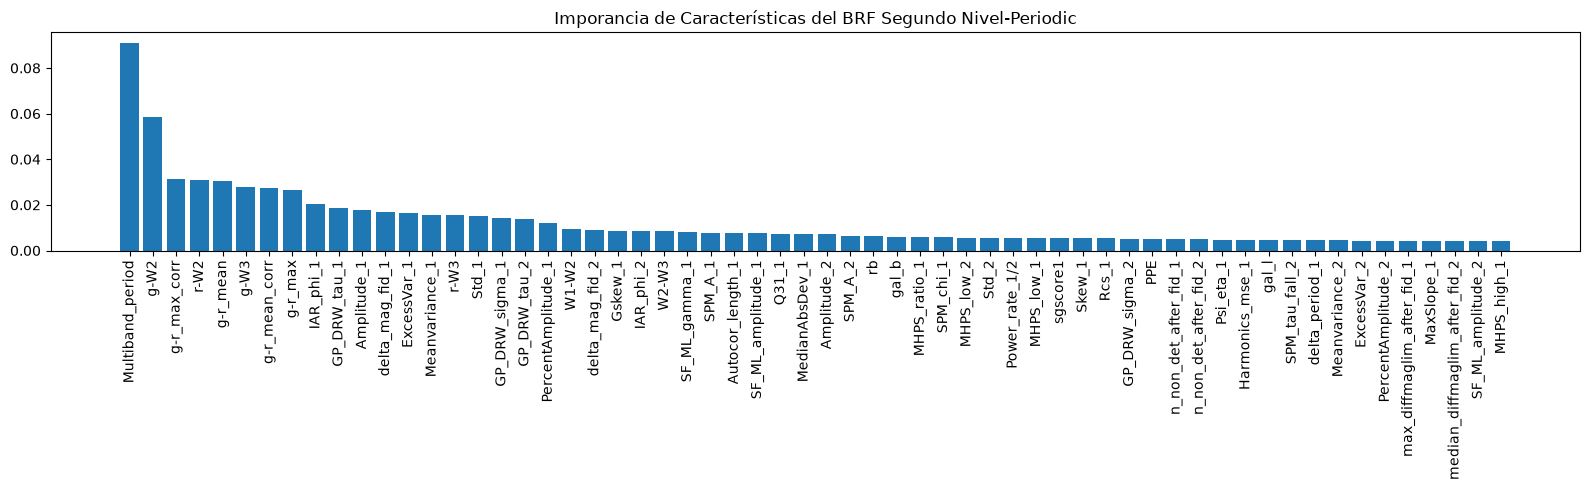

In [31]:
plot_feature_importances(BRF2_periodic, features_periodic, "Imporancia de Características del BRF Segundo Nivel-Periodic")

### BRF Stochastic

In [32]:
BRF2_stochastic = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_stochastic.fit(X_tr_Stochastic, y_tr_Stochastic)

y_true_stochastic, y_pred_stochastic = y_ts2, BRF2_stochastic.predict(X_ts_Stochastic)
y_pred_proba_stochastic = BRF2_stochastic.predict_proba(X_ts_Stochastic)

#organizar por probabilidad
classes_order_proba_stochastic = BRF2_stochastic.classes_
print(classes_order_proba_stochastic)

features_stochastic = list(X_tr_Stochastic)

['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO']


W1-W2 & 0.066
g-r_mean_corr & 0.040
sgscore1 & 0.039
g-W2 & 0.039
g-W3 & 0.037
g-r_max_corr & 0.035
r-W2 & 0.034
gal_b & 0.034
W2-W3 & 0.026
g-r_mean & 0.026
Meanvariance_2 & 0.022
ExcessVar_2 & 0.021
r-W3 & 0.021
delta_mag_fid_2 & 0.019
g-r_max & 0.018
Amplitude_2 & 0.018
SPM_A_2 & 0.017
PercentAmplitude_2 & 0.015
delta_mag_fid_1 & 0.015
Std_2 & 0.014
GP_DRW_sigma_2 & 0.013
IAR_phi_1 & 0.013
ExcessVar_1 & 0.012
SPM_A_1 & 0.012
Pvar_2 & 0.010
Amplitude_1 & 0.010
IAR_phi_2 & 0.009
MedianAbsDev_2 & 0.009
Q31_2 & 0.009
Std_1 & 0.008


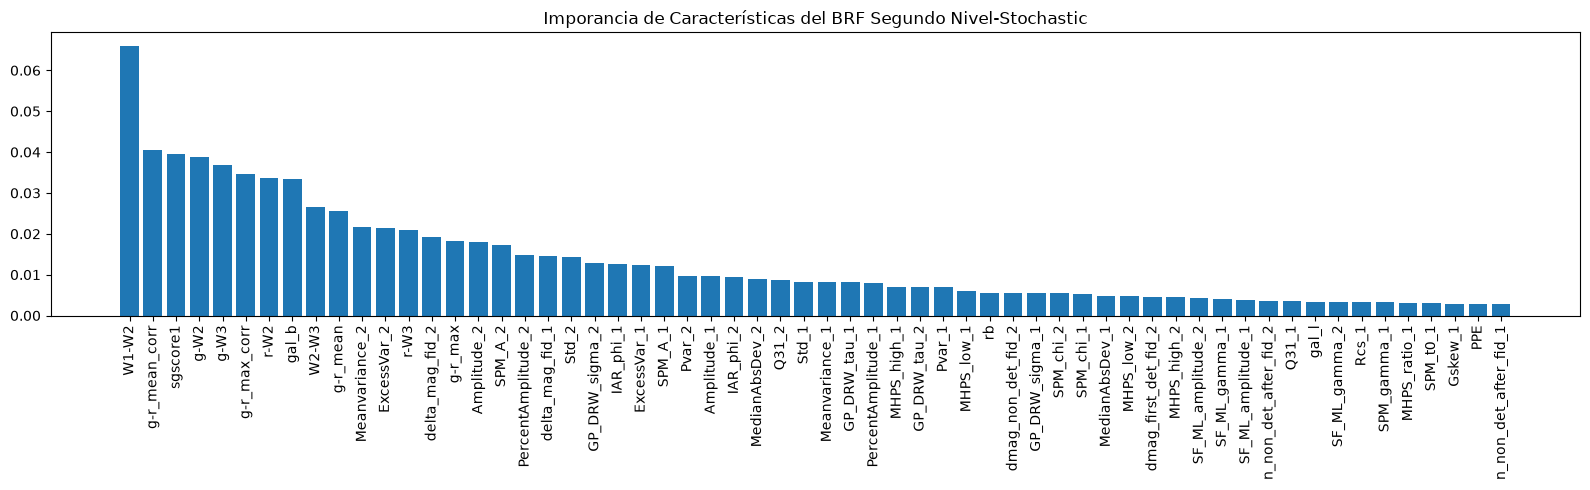

In [33]:
plot_feature_importances(BRF2_stochastic, features_stochastic, "Imporancia de Características del BRF Segundo Nivel-Stochastic")

### BRF Transient

In [34]:
BRF2_transient = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            class_weight='balanced_subsample',
            bootstrap=True,
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1)

BRF2_transient.fit(X_tr_Transient, y_tr_Transient)

y_true_transient, y_pred_transient = y_ts2, BRF2_transient.predict(X_ts_Transient)
y_pred_proba_transient = BRF2_transient.predict_proba(X_ts_Transient)

#organizar por probabilidad
classes_order_proba_transient = BRF2_transient.classes_
print(classes_order_proba_transient)

features_transient = list(X_tr_Transient)

['SLSN' 'SNII' 'SNIa' 'SNIbc']


SPM_beta_2 & 0.036
SPM_t0_1 & 0.035
SPM_tau_rise_2 & 0.024
SPM_t0_2 & 0.024
g-r_max & 0.024
LinearTrend_2 & 0.023
AndersonDarling_2 & 0.018
SPM_tau_rise_1 & 0.017
SPM_beta_1 & 0.016
dmag_first_det_fid_1 & 0.016
MHPS_ratio_1 & 0.016
SPM_tau_fall_1 & 0.016
g-r_mean & 0.015
MHPS_low_1 & 0.013
LinearTrend_1 & 0.012
SPM_tau_fall_2 & 0.012
IAR_phi_2 & 0.011
SPM_gamma_2 & 0.010
SPM_gamma_1 & 0.010
MHPS_ratio_2 & 0.009
SF_ML_gamma_1 & 0.009
Skew_2 & 0.009
SPM_A_2 & 0.009
MHPS_low_2 & 0.008
Power_rate_4 & 0.008
dmag_first_det_fid_2 & 0.008
Gskew_2 & 0.008
sgscore1 & 0.008
Harmonics_mag_5_1 & 0.008
dmag_non_det_fid_1 & 0.007


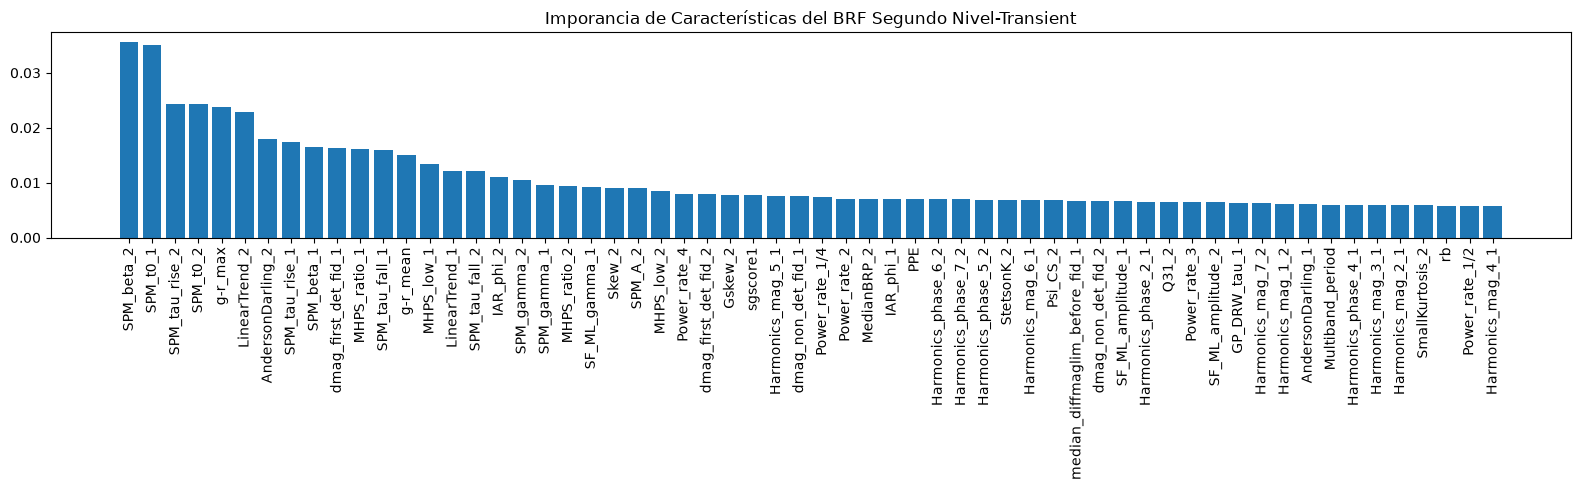

In [35]:
plot_feature_importances(BRF2_transient, features_transient, "Imporancia de Características del BRF Segundo Nivel-Transient")

### Determinar la Clase a Partir de Probabilidades

La subclase a la que pertenece cada fuente se determina mediante las probabilidades obtenidas en el BRF del primer nivel multiplicada por el BRF del segundo nivel correspondiente a la clase del primer nivel. Por ejemplo la probabilidad de que un objeto sea categorizado como blazar es

$P(\text{Blazar}) = P_{top}(\text{Sthocastic})*P_s(\text{Blazar})$

donde $P_s$ corresponde al BRF estocástico y $P_top$ a la probabilidad de ser estocástico en el primer nivel. Para el RRL correspondería a

$P(\text{RRL}) = P_{top}(\text{Periodic})*P_p(\text{RRL})$

La probabilidad $P$ mayor corresponderá a la subclase que se le asigna a la instancia

In [36]:
# generar probabilidades finales

#multiplicar la probabilidad del primer nivel por la del segundo
prob_periodic = y_pred_proba_periodic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Periodic')[0][0]].T[:, np.newaxis]
prob_stochastic = y_pred_proba_stochastic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Stochastic')[0][0]].T[:, np.newaxis]
prob_trainsient = y_pred_proba_transient*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Transient')[0][0]].T[:, np.newaxis]

#matriz final de probabilidades
#una columna para cada subclase, una fila para cada instancia
prob_final = np.concatenate((prob_stochastic,prob_trainsient,prob_periodic),axis=1)
print(f"Tamaño de Matriz de probabilidades: ", prob_final.shape)

#veificar funcionamiento adecuado. Suma las filas, la suma debe ser 1
print(f"Suma de columnas: {np.sum(prob_final,axis=1)}", f"Promedio: {np.mean(np.sum(prob_final,axis=1))}", f"Desviación Estándar: {np.std(np.sum(prob_final,axis=1))}")

#organizar los nombres de las clases igual que en prob_final
prob_final_class_names = np.concatenate((classes_order_proba_stochastic,classes_order_proba_transient,classes_order_proba_periodic))
print(prob_final_class_names)

#extrae la probabilidad mayor en cada fila y el nombre de la lase a la que corresponde
class_final_proba = np.amax(prob_final,axis=1)
class_final_index = np.argmax(prob_final,axis=1)
class_final_name = [prob_final_class_names[x] for x in class_final_index]

Tamaño de Matriz de probabilidades:  (24700, 15)
Suma de columnas: [1. 1. 1. ... 1. 1. 1.] Promedio: 1.0 Desviación Estándar: 7.89894097872551e-17
['AGN' 'Blazar' 'CV/Nova' 'QSO' 'YSO' 'SLSN' 'SNII' 'SNIa' 'SNIbc' 'CEP'
 'DSCT' 'E' 'LPV' 'Periodic-Other' 'RRL']


                precision    recall  f1-score   support

           AGN       0.64      0.84      0.73       902
        Blazar       0.47      0.70      0.57       242
           CEP       0.21      0.70      0.32       127
       CV/Nova       0.65      0.62      0.64       183
          DSCT       0.22      0.79      0.34       155
             E       0.94      0.79      0.86      7670
           LPV       0.99      0.98      0.98      2751
Periodic-Other       0.14      0.66      0.23       238
           QSO       0.97      0.89      0.93      5291
           RRL       0.95      0.89      0.92      6432
          SLSN       0.33      1.00      0.50         2
          SNII       0.75      0.63      0.68        75
          SNIa       0.87      0.83      0.85       258
         SNIbc       0.14      0.62      0.22        13
           YSO       0.78      0.79      0.79       361

      accuracy                           0.86     24700
     macro avg       0.60      0.78      0.64 

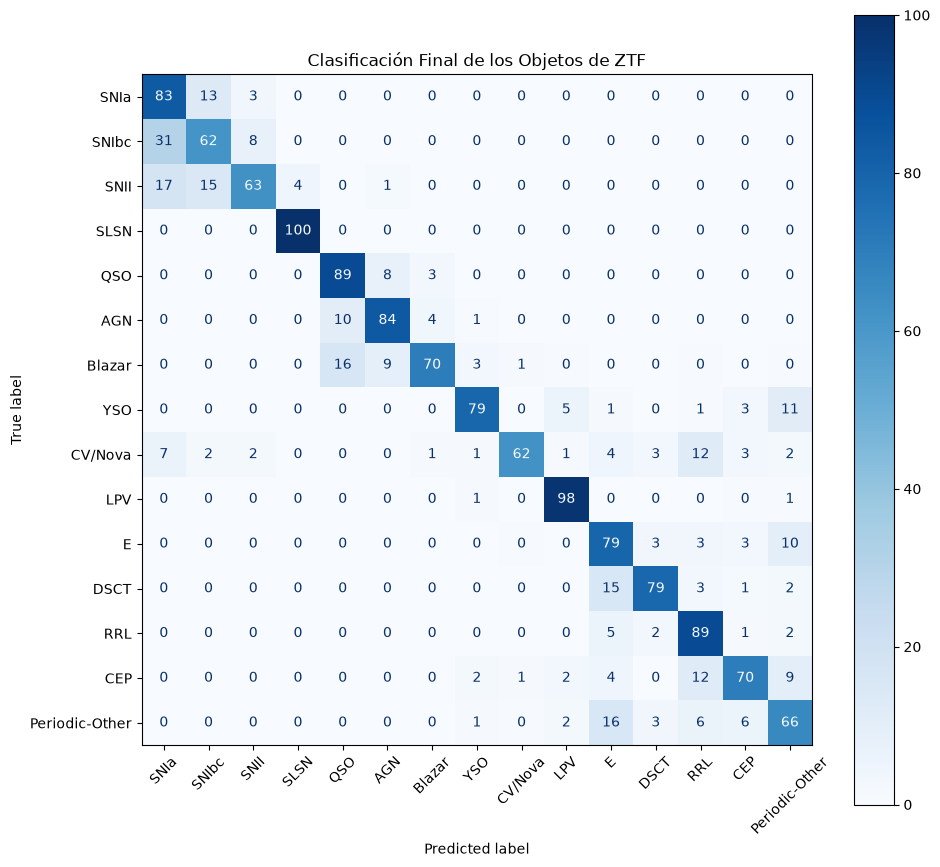

In [37]:
plot_confusionMatrix(y_ts2, class_final_name, labels_classALeRCE, "Clasificación Final de los Objetos de ZTF")

# BRF de un Nivel

El articulo aplica el BRF empleando un solo nivel para verificar si su desempeño mejora o empeora respecto al BRF de dos niveles implementado anteriormente, ya que este es más rápido de hacer.

In [38]:
BRF_unic = RandomForestClassifier(
            n_estimators=500,
            max_features='sqrt',
            max_depth=None,
            n_jobs=-1,
            bootstrap=True,
            class_weight='balanced_subsample',
            criterion='entropy',
            min_samples_split=2,
            min_samples_leaf=1
    )

BRF_unic.fit(X_tr, y_tr2)  # Se entrena directamente con las 15 subclases

y_true_unic, y_pred_unic = y_ts2, BRF_unic.predict(X_ts)

                precision    recall  f1-score   support

           AGN       0.59      0.73      0.66       902
        Blazar       0.26      0.61      0.37       242
           CEP       0.13      0.64      0.22       127
       CV/Nova       0.39      0.70      0.50       183
          DSCT       0.07      0.83      0.13       155
             E       0.94      0.61      0.74      7670
           LPV       0.99      0.89      0.94      2751
Periodic-Other       0.08      0.64      0.15       238
           QSO       0.96      0.86      0.90      5291
           RRL       0.95      0.74      0.83      6432
          SLSN       0.18      1.00      0.31         2
          SNII       0.77      0.59      0.67        75
          SNIa       0.86      0.77      0.81       258
         SNIbc       0.08      0.46      0.14        13
           YSO       0.33      0.78      0.46       361

      accuracy                           0.74     24700
     macro avg       0.51      0.72      0.52 

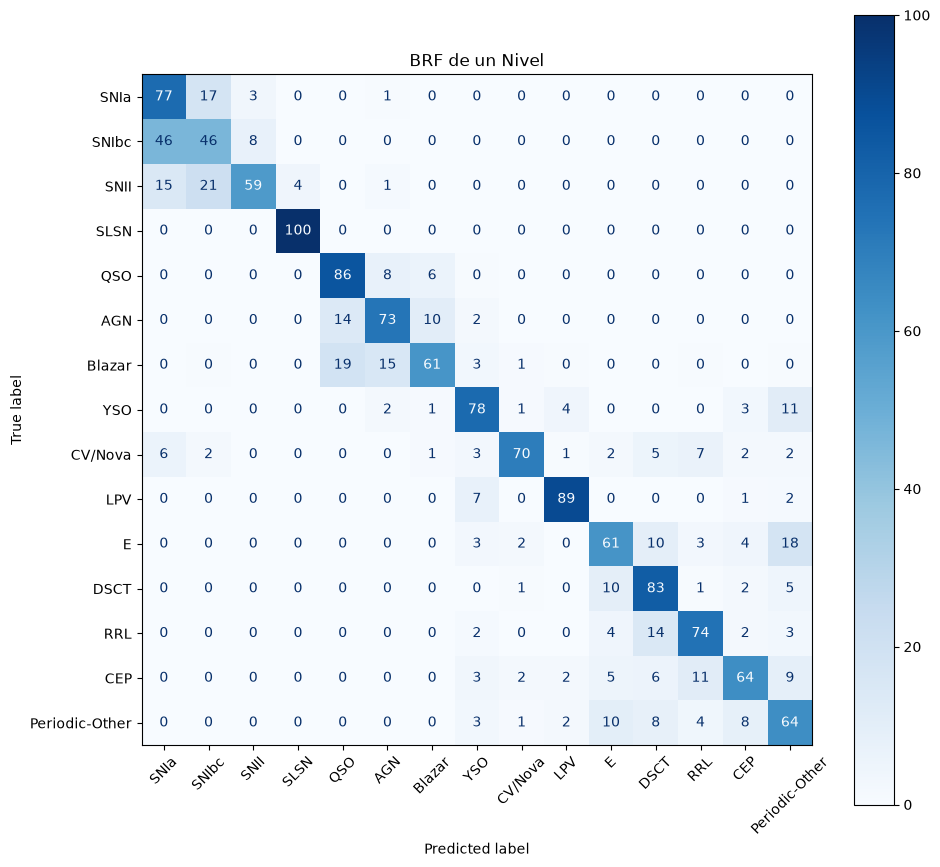

In [39]:
plot_confusionMatrix(y_true_unic, y_pred_unic, labels_classALeRCE, "BRF de un Nivel")

# Definir Función del BRF de dos niveles (para simplicidad)

In [40]:
def BRF_twolevels(X_tr, y_tr1, y_tr2, 
                  X_ts, y_ts1, y_ts2):

    #---------------------------------------------------
    #        División de Datos Para Segundo Nivel
    #---------------------------------------------------
    X_tr_Stochastic = X_tr.loc[y_tr1 == 'Stochastic', :]
    y_tr_Stochastic = y_tr2.loc[y_tr1 == 'Stochastic']
    
    X_tr_Periodic = X_tr.loc[y_tr1 == 'Periodic', :]
    y_tr_Periodic = y_tr2.loc[y_tr1 == 'Periodic']
    
    X_tr_Transient = X_tr.loc[y_tr1 == 'Transient', :]
    y_tr_Transient = y_tr2.loc[y_tr1 == 'Transient']
    
    X_ts_Stochastic = X_ts
    X_ts_Periodic = X_ts
    X_ts_Transient = X_ts
        
    #---------------------------------------------------
    #                  BRF Primer Nivel
    #---------------------------------------------------
    BRF1 = RandomForestClassifier(
                n_estimators=500,
                max_features='sqrt',
                max_depth=None,
                n_jobs=-1,
                bootstrap=True,
                class_weight='balanced_subsample',
                criterion='entropy',
                min_samples_split=2,
                min_samples_leaf=1
        )
    
    BRF1.fit(X_tr, y_tr1)
    
    y_true, y_pred = y_ts1, BRF1.predict(X_ts)
    y_pred_proba_BRF1 = BRF1.predict_proba(X_ts)
    
    #organizar por probabilidad
    classes_order_proba_BRF1 = BRF1.classes_
    
    features = list(X_tr)

    
    #---------------------------------------------------
    #                  BRF Periodic
    #---------------------------------------------------
    BRF2_periodic = RandomForestClassifier(
                n_estimators=500,
                max_features='sqrt',
                max_depth=None,
                n_jobs=-1,
                class_weight='balanced_subsample',
                bootstrap=True,
                criterion='entropy',
                min_samples_split=2,
                min_samples_leaf=1)
    
    BRF2_periodic.fit(X_tr_Periodic, y_tr_Periodic)
    
    y_true_periodic, y_pred_periodic = y_ts2, BRF2_periodic.predict(X_ts_Periodic)
    y_pred_proba_periodic = BRF2_periodic.predict_proba(X_ts_Periodic)
    
    #organizar por probabilidad
    classes_order_proba_periodic = BRF2_periodic.classes_
    
    features_periodic = list(X_tr_Periodic)


    #---------------------------------------------------
    #                  BRF Stochastic
    #---------------------------------------------------
    BRF2_stochastic = RandomForestClassifier(
                n_estimators=500,
                max_features='sqrt',
                max_depth=None,
                n_jobs=-1,
                class_weight='balanced_subsample',
                bootstrap=True,
                criterion='entropy',
                min_samples_split=2,
                min_samples_leaf=1)
    
    BRF2_stochastic.fit(X_tr_Stochastic, y_tr_Stochastic)
    
    y_true_stochastic, y_pred_stochastic = y_ts2, BRF2_stochastic.predict(X_ts_Stochastic)
    y_pred_proba_stochastic = BRF2_stochastic.predict_proba(X_ts_Stochastic)
    
    #organizar por probabilidad
    classes_order_proba_stochastic = BRF2_stochastic.classes_
    
    features_stochastic = list(X_tr_Stochastic)


    #---------------------------------------------------
    #                  BRF Transient
    #---------------------------------------------------
    BRF2_transient = RandomForestClassifier(
                n_estimators=500,
                max_features='sqrt',
                max_depth=None,
                n_jobs=-1,
                class_weight='balanced_subsample',
                bootstrap=True,
                criterion='entropy',
                min_samples_split=2,
                min_samples_leaf=1)
    
    BRF2_transient.fit(X_tr_Transient, y_tr_Transient)
    
    y_true_transient, y_pred_transient = y_ts2, BRF2_transient.predict(X_ts_Transient)
    y_pred_proba_transient = BRF2_transient.predict_proba(X_ts_Transient)
    
    #organizar por probabilidad
    classes_order_proba_transient = BRF2_transient.classes_
    
    features_transient = list(X_tr_Transient)

    
    #---------------------------------------------------
    #                  BRF Transient
    #---------------------------------------------------
    #multiplicar la probabilidad del primer nivel por la del segundo
    prob_periodic = y_pred_proba_periodic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Periodic')[0][0]].T[:, np.newaxis]
    prob_stochastic = y_pred_proba_stochastic*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Stochastic')[0][0]].T[:, np.newaxis]
    prob_trainsient = y_pred_proba_transient*y_pred_proba_BRF1[:,np.where(classes_order_proba_BRF1=='Transient')[0][0]].T[:, np.newaxis]
    
    #matriz final de probabilidades
    #una columna para cada subclase, una fila para cada instancia
    prob_final = np.concatenate((prob_stochastic,prob_trainsient,prob_periodic),axis=1)
    
    #organizar los nombres de las clases igual que en prob_final
    prob_final_class_names = np.concatenate((classes_order_proba_stochastic,classes_order_proba_transient,classes_order_proba_periodic))
    
    #extrae la probabilidad mayor en cada fila y el nombre de la lase a la que corresponde
    class_final_proba = np.amax(prob_final,axis=1)
    class_final_index = np.argmax(prob_final,axis=1)
    class_final_name = [prob_final_class_names[x] for x in class_final_index]

    
    
    #Predicciones finales del 2do nivel 
    return(class_final_name)

# BRF sin Datos de AllWISE

A parte de las curvas de luminocidad extraidas de la base de datos de ZTF, los autores tambien emplean magnitudes para 3 distintos filtros de longitudes de onda registradas por el telescopio WISE de la Nasa, que se encuentran en la base de datos AllWISE.

Los autores implementan 6 características que corresponden a comparaciones entre las bandas r y g del ZTF y las magnitudes de AllWISE. Para averiguar la importancia de incluir estas comparaciones, realizaron un modelo BRF excluyendo las características de AllWISE.

In [41]:
# Características relacionadas con AllWISE
WISE_features = ['W1-W2',
                 'W2-W3',
                 'r-W3',
                 'r-W2',
                 'g-W3',
                 'g-W2',]

X_tr_WISE = X_tr.drop(columns = WISE_features)
X_ts_WISE = X_ts.drop(columns = WISE_features)

print(X_tr_WISE.shape, X_ts_WISE.shape )

(98796, 146) (24700, 146)


                precision    recall  f1-score   support

           AGN       0.58      0.80      0.67       902
        Blazar       0.34      0.49      0.40       242
           CEP       0.17      0.65      0.26       127
       CV/Nova       0.65      0.64      0.65       183
          DSCT       0.22      0.78      0.34       155
             E       0.94      0.76      0.84      7670
           LPV       0.96      0.96      0.96      2751
Periodic-Other       0.12      0.62      0.21       238
           QSO       0.95      0.88      0.91      5291
           RRL       0.94      0.88      0.91      6432
          SLSN       0.29      1.00      0.44         2
          SNII       0.74      0.57      0.65        75
          SNIa       0.88      0.82      0.85       258
         SNIbc       0.12      0.62      0.20        13
           YSO       0.54      0.58      0.56       361

      accuracy                           0.83     24700
     macro avg       0.56      0.74      0.59 

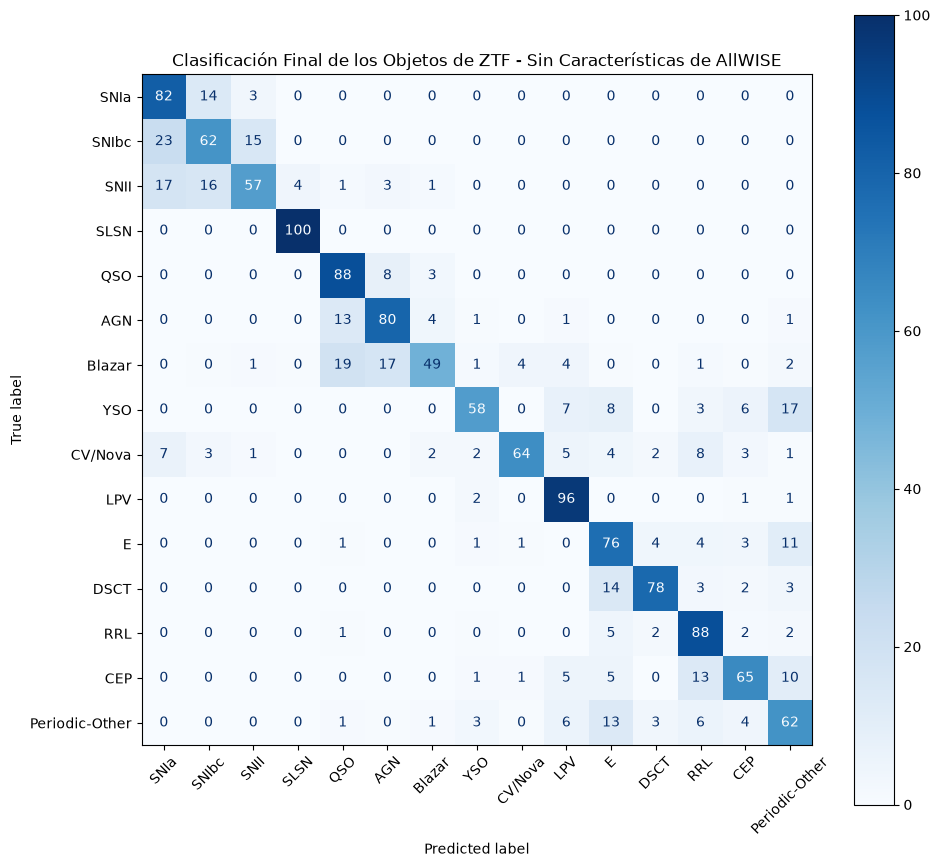

In [42]:
y_pred_WISE = BRF_twolevels(X_tr_WISE, y_tr1, y_tr2,
                          X_ts_WISE, y_ts1, y_ts2)

plot_confusionMatrix(y_ts2, y_pred_WISE, labels_classALeRCE, "Clasificación Final de los Objetos de ZTF - Sin Características de AllWISE")

# Relevancia de la Magnitud en el Desempeño del Modelo

Con el fin de analizar como influye de la magnitud (luminosidad) de los objetos en el desempeño del clasificador, los autores juntaron los datos en intervalos de magnitudes de 0.5 entre 13 y 21. Se realizan 3 dataframes diferentes excluyendo características de cada banda:
- Solo características de banda g
- Solo características de banda r
- Todas las características gr (el mimo modelo aplicado al inicio)

Se extraen las clases reales y las predichas de cada modelo, se dividen en los intervalos de magnitudes y se calcula el recall correspondiente a dicho intervalo para cada banda

### Modelo de gr

In [43]:
y_pred_gr = BRF_twolevels(X_tr, y_tr1, y_tr2,
                        X_ts, y_ts1, y_ts2)

### Modelo de g

In [44]:
X_tr_g = X_tr.loc[:, ~X_tr.columns.str.endswith("_2")]
X_ts_g = X_ts.loc[:, ~X_ts.columns.str.endswith("_2")]

y_pred_g = BRF_twolevels(X_tr_g, y_tr1, y_tr2,
                        X_ts_g, y_ts1, y_ts2)

### Modelo de r

In [45]:
X_tr_r = X_tr.loc[:, ~X_tr.columns.str.endswith("_1")]
X_ts_r = X_ts.loc[:, ~X_ts.columns.str.endswith("_1")]

y_pred_r = BRF_twolevels(X_tr_r, y_tr1, y_tr2,
                        X_ts_r, y_ts1, y_ts2)

## Dataframe con los conteos de cada clase

In [46]:
df_y_pred_gr = pd.DataFrame(y_pred_gr)
df_y_pred_gr = df_y_pred_gr.rename(columns={0: 'pred_gr'})

df_y_pred_g = pd.DataFrame(y_pred_g)
df_y_pred_g = df_y_pred_g.rename(columns={0: 'pred_g'})

df_y_pred_r = pd.DataFrame(y_pred_r)
df_y_pred_r = df_y_pred_r.rename(columns={0: 'pred_r'})


df_y_ts2 = pd.DataFrame(y_ts2)

df_mag = df_labeled_all[['Mean_1', 'Mean_2']]

temp = df_y_ts2.join(df_mag, how="inner")
temp = temp.reset_index(drop=True)

In [47]:
results_mag = df_y_pred_gr.join([df_y_pred_g, df_y_pred_r, temp])
results_mag.fillna(-999)

,pred_gr,pred_g,pred_r,classALeRCE,Mean_1,Mean_2
0,RRL,RRL,RRL,E,17.375326,17.352625
1,QSO,QSO,QSO,QSO,19.166294,-999.000000
2,RRL,RRL,RRL,RRL,18.768480,18.503406
3,E,E,E,E,16.069180,15.517135
4,LPV,LPV,LPV,LPV,15.645573,-999.000000
...,...,...,...,...,...,...
24695,QSO,QSO,QSO,QSO,18.398159,18.474816
24696,RRL,RRL,RRL,RRL,17.554959,17.301868
24697,E,DSCT,E,DSCT,13.259290,12.527378
24698,E,E,E,E,16.364815,16.043290


## Dividir de acuerdo a la magnitud

In [48]:
bins_mag = np.arange(13, 21, 0.5)

results_mag['mag_range_g'] = pd.cut(results_mag['Mean_1'], bins=bins_mag)
results_mag['mag_range_r'] = pd.cut(results_mag['Mean_2'], bins=bins_mag)
results_mag.head(3)

,pred_gr,pred_g,pred_r,classALeRCE,Mean_1,Mean_2,mag_range_g,mag_range_r
0,RRL,RRL,RRL,E,17.375326,17.352625,"(17.0, 17.5]","(17.0, 17.5]"
1,QSO,QSO,QSO,QSO,19.166294,NaN,"(19.0, 19.5]",NaN
2,RRL,RRL,RRL,RRL,18.768480,18.503406,"(18.5, 19.0]","(18.5, 19.0]"


## Calcular para cada intervalo

In [49]:
recall_gr = []
recall_g = []
recall_r = []

magnitude_g = []
magnitude_r = []

In [50]:
for mag_range, group in results_mag.groupby('mag_range_g'):     #agrupar e iterar por intervalo para las magnitudes en g (aplica para gr)

    # añadir el recall para cada intervalo y para cada clase
    recalls_gr = metrics.recall_score(group['classALeRCE'], 
                            group['pred_gr'], 
                            labels=labels_classALeRCE, 
                            average=None, 
                            zero_division=0)

    recalls_g = metrics.recall_score(group['classALeRCE'], 
                            group['pred_g'], 
                            labels=labels_classALeRCE, 
                            average=None, 
                            zero_division=0)

    recall_gr.append(recalls_gr)
    recall_g.append(recalls_g)
    
    #extrar un bode del intervalo
    magnitude_g.append(mag_range.left)


for mag_range, group in results_mag.groupby('mag_range_r'):     #agrupar e iterar por intervalo para las magnitudes en r

    # añadir el recall para cada intervalo y para cada clase
    recalls_r = metrics.recall_score(group['classALeRCE'], 
                            group['pred_r'], 
                            labels=labels_classALeRCE, 
                            average=None, 
                            zero_division=0)

    recall_r.append(recalls_r)
    
    #extrar un bode del intervalo
    magnitude_r.append(mag_range.left)

In [51]:
magnitude_g = pd.DataFrame(magnitude_g, columns=['ranges'])
magnitude_r = pd.DataFrame(magnitude_r, columns=['ranges'])

recall_gr = pd.DataFrame(recall_gr, columns=labels_classALeRCE)
recall_gr = recall_gr.join(magnitude_g)

recall_g = pd.DataFrame(recall_g, columns=labels_classALeRCE)
recall_g = recall_g.join(magnitude_g)

recall_r = pd.DataFrame(recall_r, columns=labels_classALeRCE)
recall_r = recall_r.join(magnitude_r)

## Gráfica

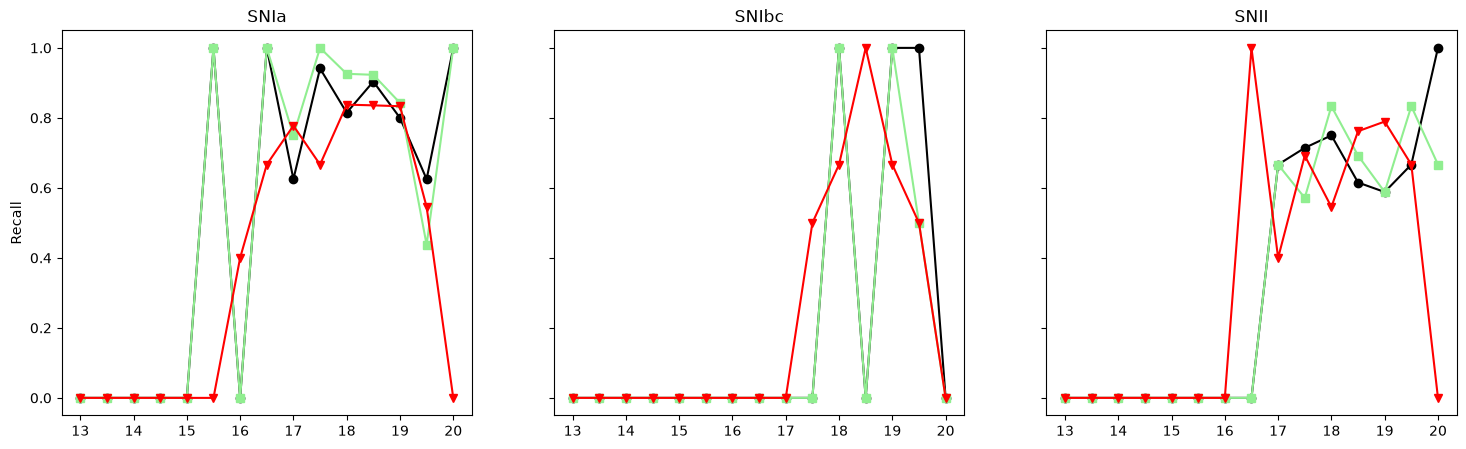

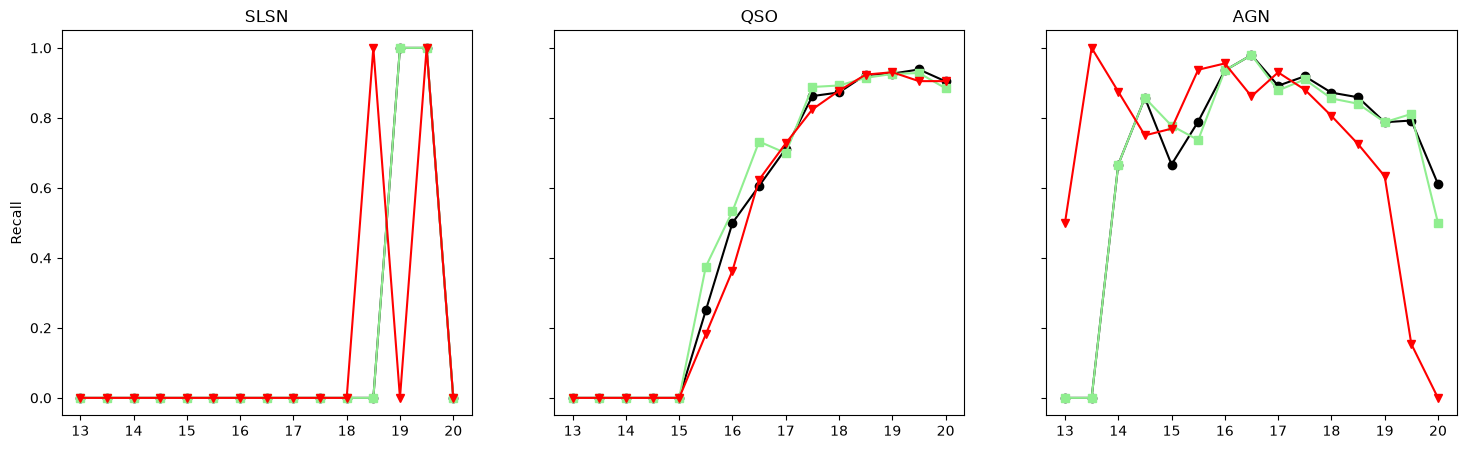

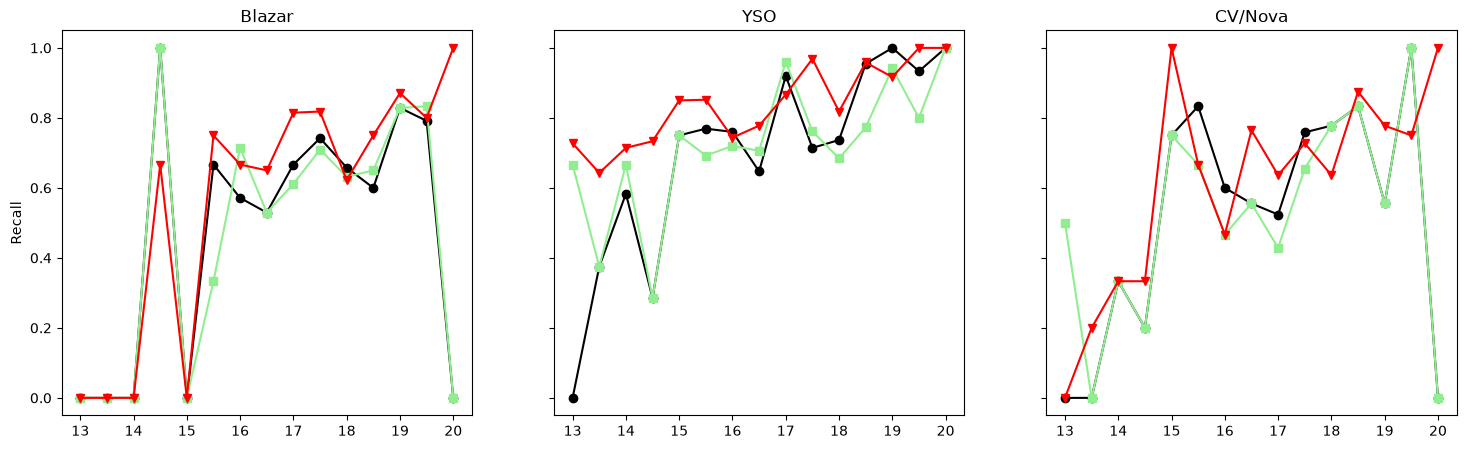

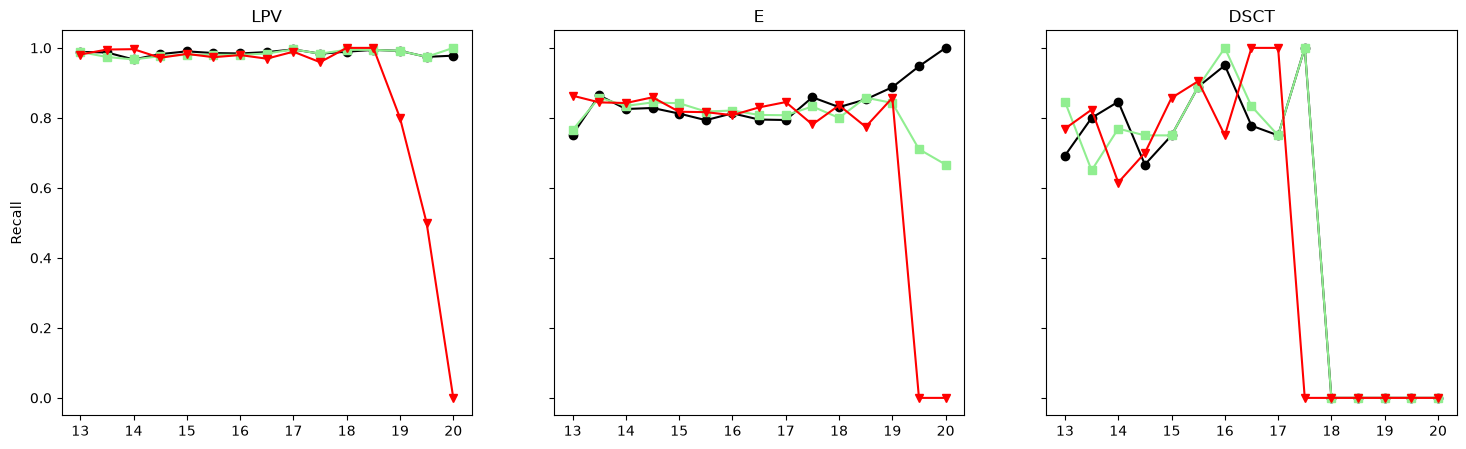

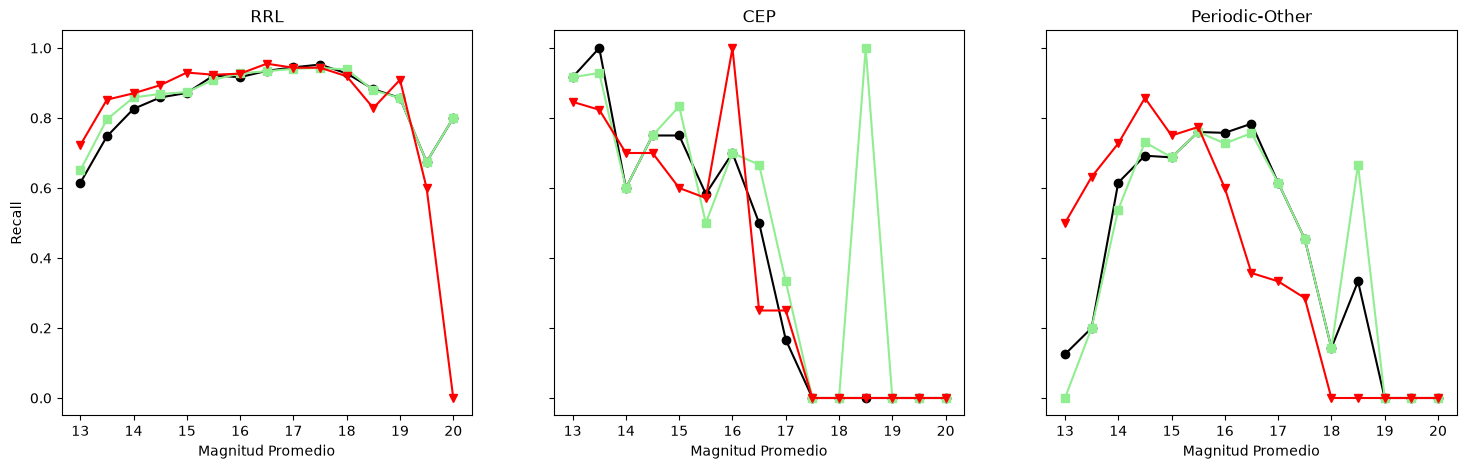

In [52]:
for n in [0, 3, 6, 9, 12]:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    
    axes[0].plot(recall_gr['ranges'], recall_gr[labels_classALeRCE[n]], marker='o', color='black')
    axes[0].plot(recall_g['ranges'], recall_g[labels_classALeRCE[n]], marker='s', color='lightgreen')
    axes[0].plot(recall_r['ranges'], recall_r[labels_classALeRCE[n]], marker='v', color='red')
    axes[0].set_title(labels_classALeRCE[n])
    axes[0].set_ylabel('Recall')
    
    axes[1].plot(recall_gr['ranges'], recall_gr[labels_classALeRCE[n+1]], marker='o', color='black')
    axes[1].plot(recall_g['ranges'], recall_g[labels_classALeRCE[n+1]], marker='s', color='lightgreen')
    axes[1].plot(recall_r['ranges'], recall_r[labels_classALeRCE[n+1]], marker='v', color='red')
    axes[1].set_title(labels_classALeRCE[n+1])

    axes[2].plot(recall_gr['ranges'], recall_gr[labels_classALeRCE[n+2]], marker='o', color='black')
    axes[2].plot(recall_g['ranges'], recall_g[labels_classALeRCE[n+2]], marker='s', color='lightgreen')
    axes[2].plot(recall_r['ranges'], recall_r[labels_classALeRCE[n+2]], marker='v', color='red')
    axes[2].set_title(labels_classALeRCE[n+2])
    if n==12:
        axes[0].set_xlabel('Magnitud Promedio')
        axes[1].set_xlabel('Magnitud Promedio')
        axes[2].set_xlabel('Magnitud Promedio')
    
    plt.show()

Lo que se puede extraer de aqui es que:
- Las Super Novas (SN's) son objetos de magnitud grande, basándonos en que el recall es 0 para los primeros intervalos. Caso contrario para las Cefeidas, Delta Scuti y otras fuentes periódicas.
- Para la mayoría de los objetos la magnitud no parece influir en el desempeño del clasificador, con algunas excepciones en cefeidas, QSO y otras fuentes periódicas.
- En general el desempeño en las bandas es similar.

# Guardar Dataframes

In [53]:
df_labeled_all.to_parquet('../Data_parcial2_mineria/df_labeled_all.parquet')
df_unlabeled_all.to_parquet('../Data_parcial2_mineria/df_unlabeled_all.parquet')

df_labeled.to_parquet('../Data_parcial2_mineria/df_labeled.parquet')
df_unlabeled.to_parquet('../Data_parcial2_mineria/df_unlabeled.parquet')